# Feature Engineering

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

import database

## Import raw feature data from the db

<b style="color:DodgerBlue;">Only fetches everything until the last complete month</b>

In [156]:
data = database.db_requester_fetchall(sql_script="all_MonthlyFeatures.sql")

In [157]:
arr_raw = np.array(data)
arr_raw[np.where(arr_raw == None)[0]]
# np.isnan(arr_raw)

array([['UNRATE', '2025-10-01', None, '2026-08-10 22:57:41']],
      dtype=object)

## Data prep
- Impute missing values

In [158]:
df_raw = pd.DataFrame(data, columns=['series_id', 'month_year', 'value', 'timestamp'])
df_raw['month_year'] = pd.to_datetime(df_raw['month_year'])
df_raw

,series_id,month_year,value,timestamp
0,ICSA,2000-12-01,1.730000e+06,2026-08-10 22:57:41
1,INDPRO,2000-12-01,9.234150e+01,2026-08-10 22:57:41
2,JTSJOL,2000-12-01,5.088000e+03,2026-08-10 22:57:41
3,PAYEMS,2000-12-01,1.327160e+05,2026-08-10 22:57:41
4,UNRATE,2000-12-01,3.900000e+00,2026-08-10 22:57:41
...,...,...,...,...
1530,ICSA,2026-06-01,8.900000e+05,2026-08-10 22:57:41
1531,INDPRO,2026-06-01,1.026395e+02,2026-08-10 22:57:41
1532,JTSJOL,2026-06-01,7.359000e+03,2026-08-10 22:57:41
1533,PAYEMS,2026-06-01,1.588810e+05,2026-08-10 22:57:41


In [159]:
df = df_raw.pivot(
    index='month_year',
    columns='series_id',
    values='value'
).reset_index()
df['month_year'] = df['month_year'].dt.to_period('M')
df.columns.name = None

df

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4
...,...,...,...,...,...,...
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.4
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.3
304,2026-04,831000.0,102.4196,7585.0,158798.0,4.3
305,2026-05,1058000.0,102.5606,7537.0,158861.0,4.3


<b style="color:DodgerBlue;">IMPORTANT: Do not forget to treat missing values</b>

In [160]:
df[df.isna().any(axis=1)]

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE
298,2025-10,907000.0,101.2195,7170.0,158408.0,NaN


In [161]:
features = ['ICSA', 'INDPRO', 'JTSJOL', 'PAYEMS', 'UNRATE']
df_imputed = df.copy()
df_imputed[features] = df[features].interpolate(method="linear")
df_imputed[df_imputed.isna().any(axis=1)]
# df_imputed

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE


## Feature sets, plot, and correlation analysis
- Time lagged `UNRATE`
- Normalize data
- Try converting data to a common unit e.g. rate of change

In [162]:
df_imputed[features].corr()

,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE
ICSA,1.000000,-0.427989,-0.188280,-0.284911,0.564504
INDPRO,-0.427989,1.000000,0.613091,0.715330,-0.617404
JTSJOL,-0.188280,0.613091,1.000000,0.840835,-0.605025
PAYEMS,-0.284911,0.715330,0.840835,1.000000,-0.652774
UNRATE,0.564504,-0.617404,-0.605025,-0.652774,1.000000


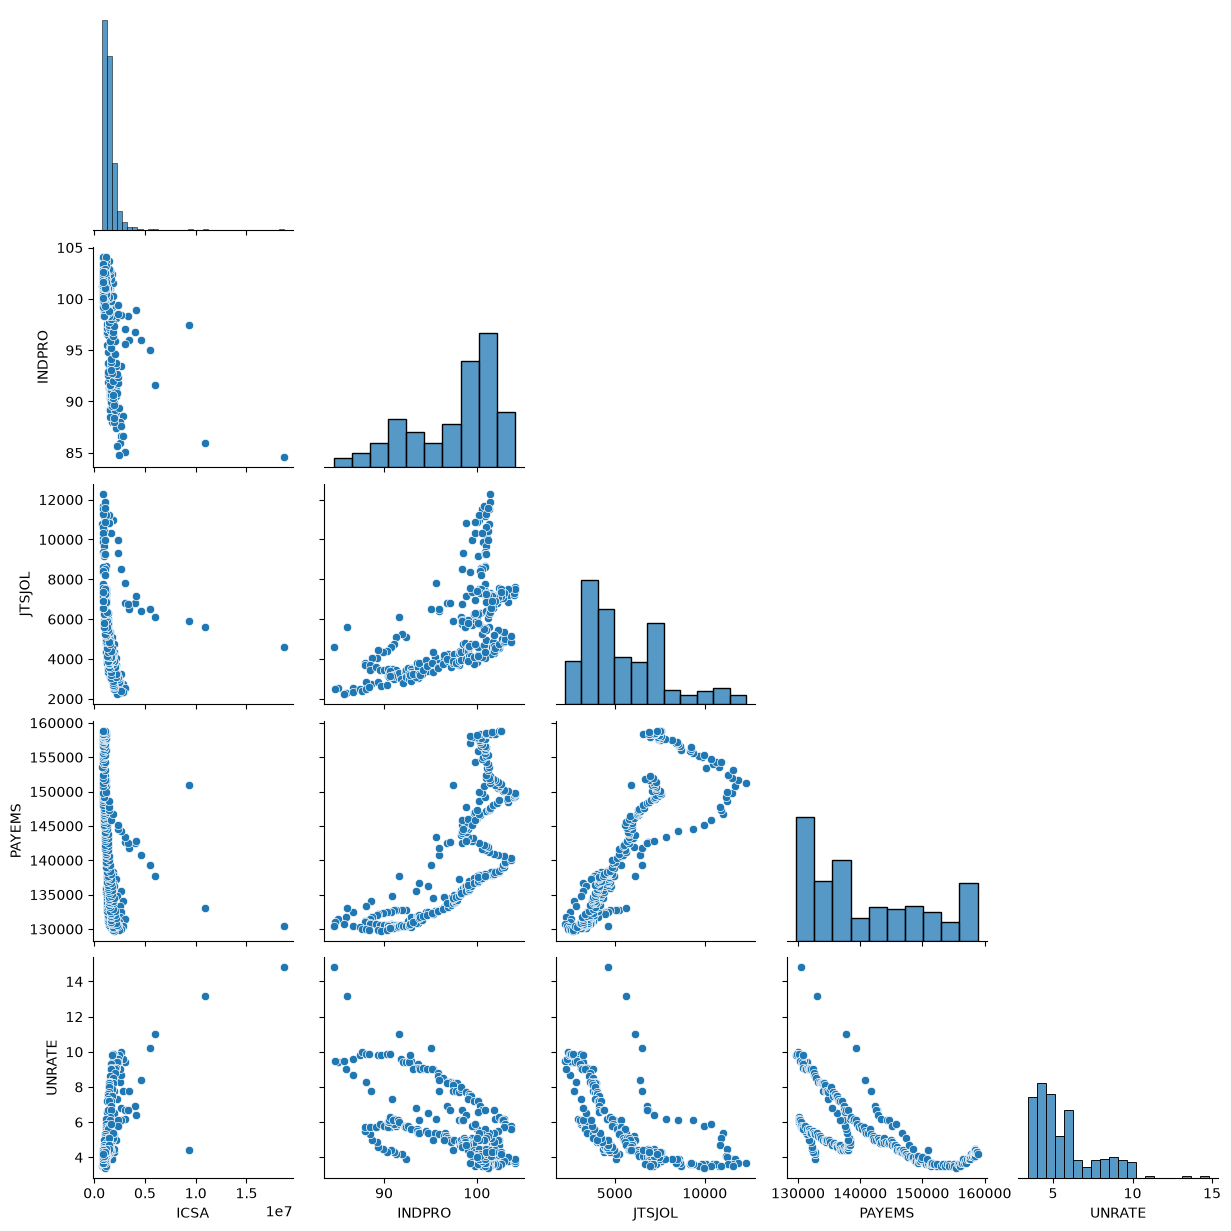

In [163]:
sns.pairplot(
    df_imputed[features],
    diag_kind="hist",
    corner=True
)

plt.show()

### Developing features with future `UNRATE` targets (1, 3, 6, 12 months)
df structure:
- base values
- four features as pct change and `UNRATE` difference
- future `UNRATE` targets
- how future `UNRATE` changes compared to current


In [164]:
time_frames = [1, 3, 6, 12]

df_features = df_imputed.copy()

# first four features as pct change
for feature in features[0:4]:
    df_features[f"{feature}_pct_change"] = df_features[feature].pct_change()

# change in UNRATE
df_features["UNRATE_change"] = df_features["UNRATE"].diff()

# future UNRATE targets
for t in time_frames:
    df_features[f"UNRATE_t+{t}"] = df_features["UNRATE"].shift(-t)
    df_features[f"UNRATE_t+{t}_change"] = df_features[f"UNRATE_t+{t}"]-df_features["UNRATE"]

df_features

,month_year,ICSA,INDPRO,JTSJOL,PAYEMS,UNRATE,ICSA_pct_change,INDPRO_pct_change,JTSJOL_pct_change,PAYEMS_pct_change,UNRATE_change,UNRATE_t+1,UNRATE_t+1_change,UNRATE_t+3,UNRATE_t+3_change,UNRATE_t+6,UNRATE_t+6_change,UNRATE_t+12,UNRATE_t+12_change
0,2000-12,1730000.0,92.3415,5088.0,132716.0,3.9,NaN,NaN,NaN,NaN,NaN,4.2,0.3,4.3,0.4,4.5,0.6,5.7,1.8
1,2001-01,1360000.0,91.9020,5234.0,132703.0,4.2,-0.213873,-0.004760,0.028695,-0.000098,0.3,4.2,0.0,4.4,0.2,4.6,0.4,5.7,1.5
2,2001-02,1485000.0,91.3034,5097.0,132788.0,4.2,0.091912,-0.006513,-0.026175,0.000641,0.0,4.3,0.1,4.3,0.1,4.9,0.7,5.7,1.5
3,2001-03,1936000.0,91.1162,4762.0,132751.0,4.3,0.303704,-0.002050,-0.065725,-0.000279,0.1,4.4,0.1,4.5,0.2,5.0,0.7,5.7,1.4
4,2001-04,1587000.0,90.7891,4615.0,132458.0,4.4,-0.180269,-0.003590,-0.030869,-0.002207,0.1,4.3,-0.1,4.6,0.2,5.3,0.9,5.9,1.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
302,2026-02,863000.0,101.9263,6922.0,158436.0,4.4,-0.185080,0.008784,-0.043923,-0.000984,0.1,4.3,-0.1,4.3,-0.1,NaN,NaN,NaN,NaN
303,2026-03,832000.0,101.6172,6887.0,158650.0,4.3,-0.035921,-0.003033,-0.005056,0.001351,-0.1,4.3,0.0,4.2,-0.1,NaN,NaN,NaN,NaN
304,2026-04,831000.0,102.4196,7585.0,158798.0,4.3,-0.001202,0.007896,0.101350,0.000933,0.0,4.3,0.0,NaN,NaN,NaN,NaN,NaN,NaN
305,2026-05,1058000.0,102.5606,7537.0,158861.0,4.3,0.273165,0.001377,-0.006328,0.000397,0.0,4.2,-0.1,NaN,NaN,NaN,NaN,NaN,NaN


**Feature sets:**

In [165]:
feature_set_levels = ['ICSA', 'INDPRO', 'JTSJOL', 'PAYEMS', 'UNRATE']
feature_set_changes = [
    'ICSA_pct_change',
    'INDPRO_pct_change',
    'JTSJOL_pct_change',
    'PAYEMS_pct_change',
    'UNRATE_change'    
]

In [168]:
feature_set_log_levels = []

for col in feature_set_levels:
    col_name = f"log10_{col}"
    feature_set_log_levels.append(col_name)
    df_features[col_name] = df_features[col].apply(np.log10)

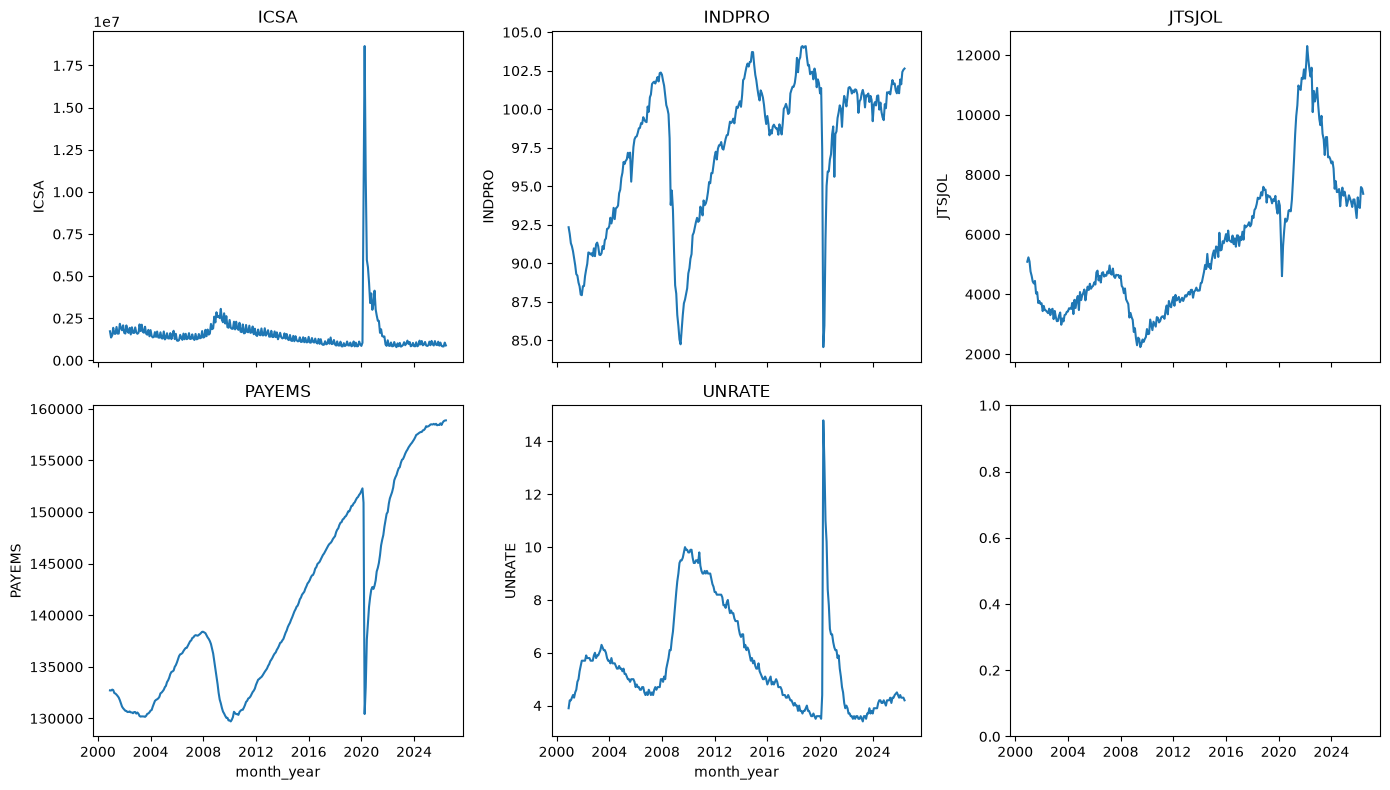

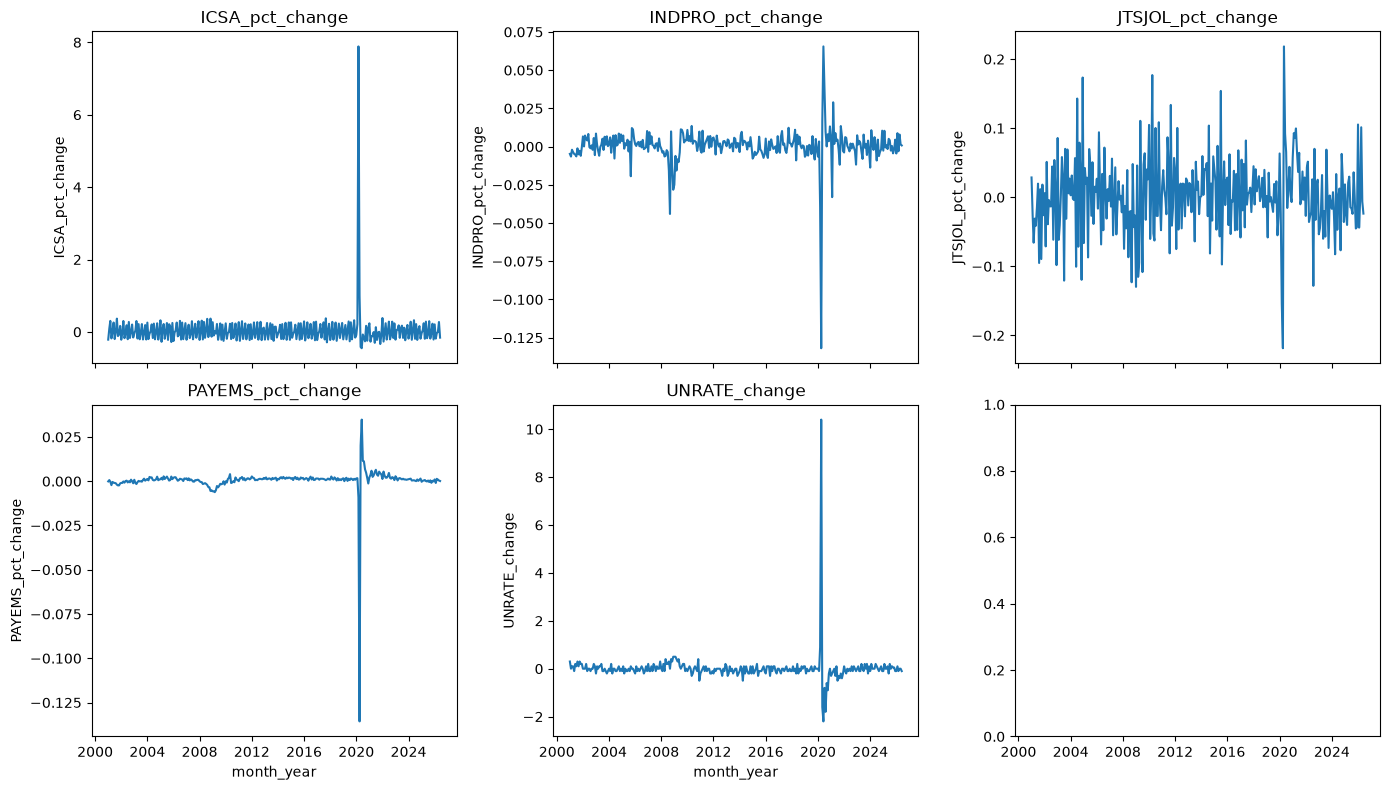

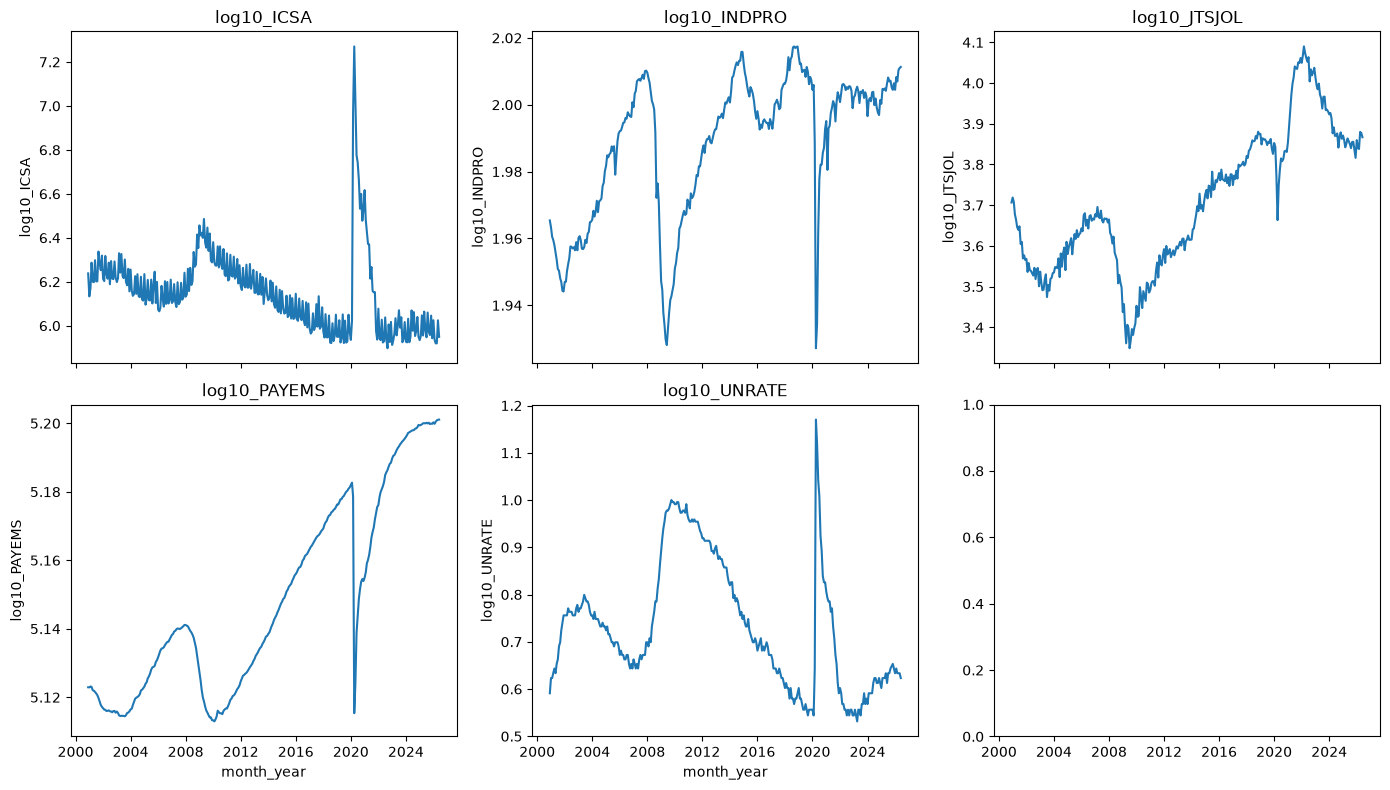

In [169]:
col_sets = [feature_set_levels, feature_set_changes, feature_set_log_levels]

for cols in col_sets:
    len_cols = len(cols)
    ncols = 3
    nrows = int(np.ceil(len_cols / ncols))

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(14, 8),
        sharex=True
    )

    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        sns.lineplot(
            data=df_features,
            x=df_features['month_year'].dt.to_timestamp(),
            y=col,
            ax=ax
        )
        ax.set_title(col)

    plt.tight_layout()
    plt.show()

**Changes set is more stable**

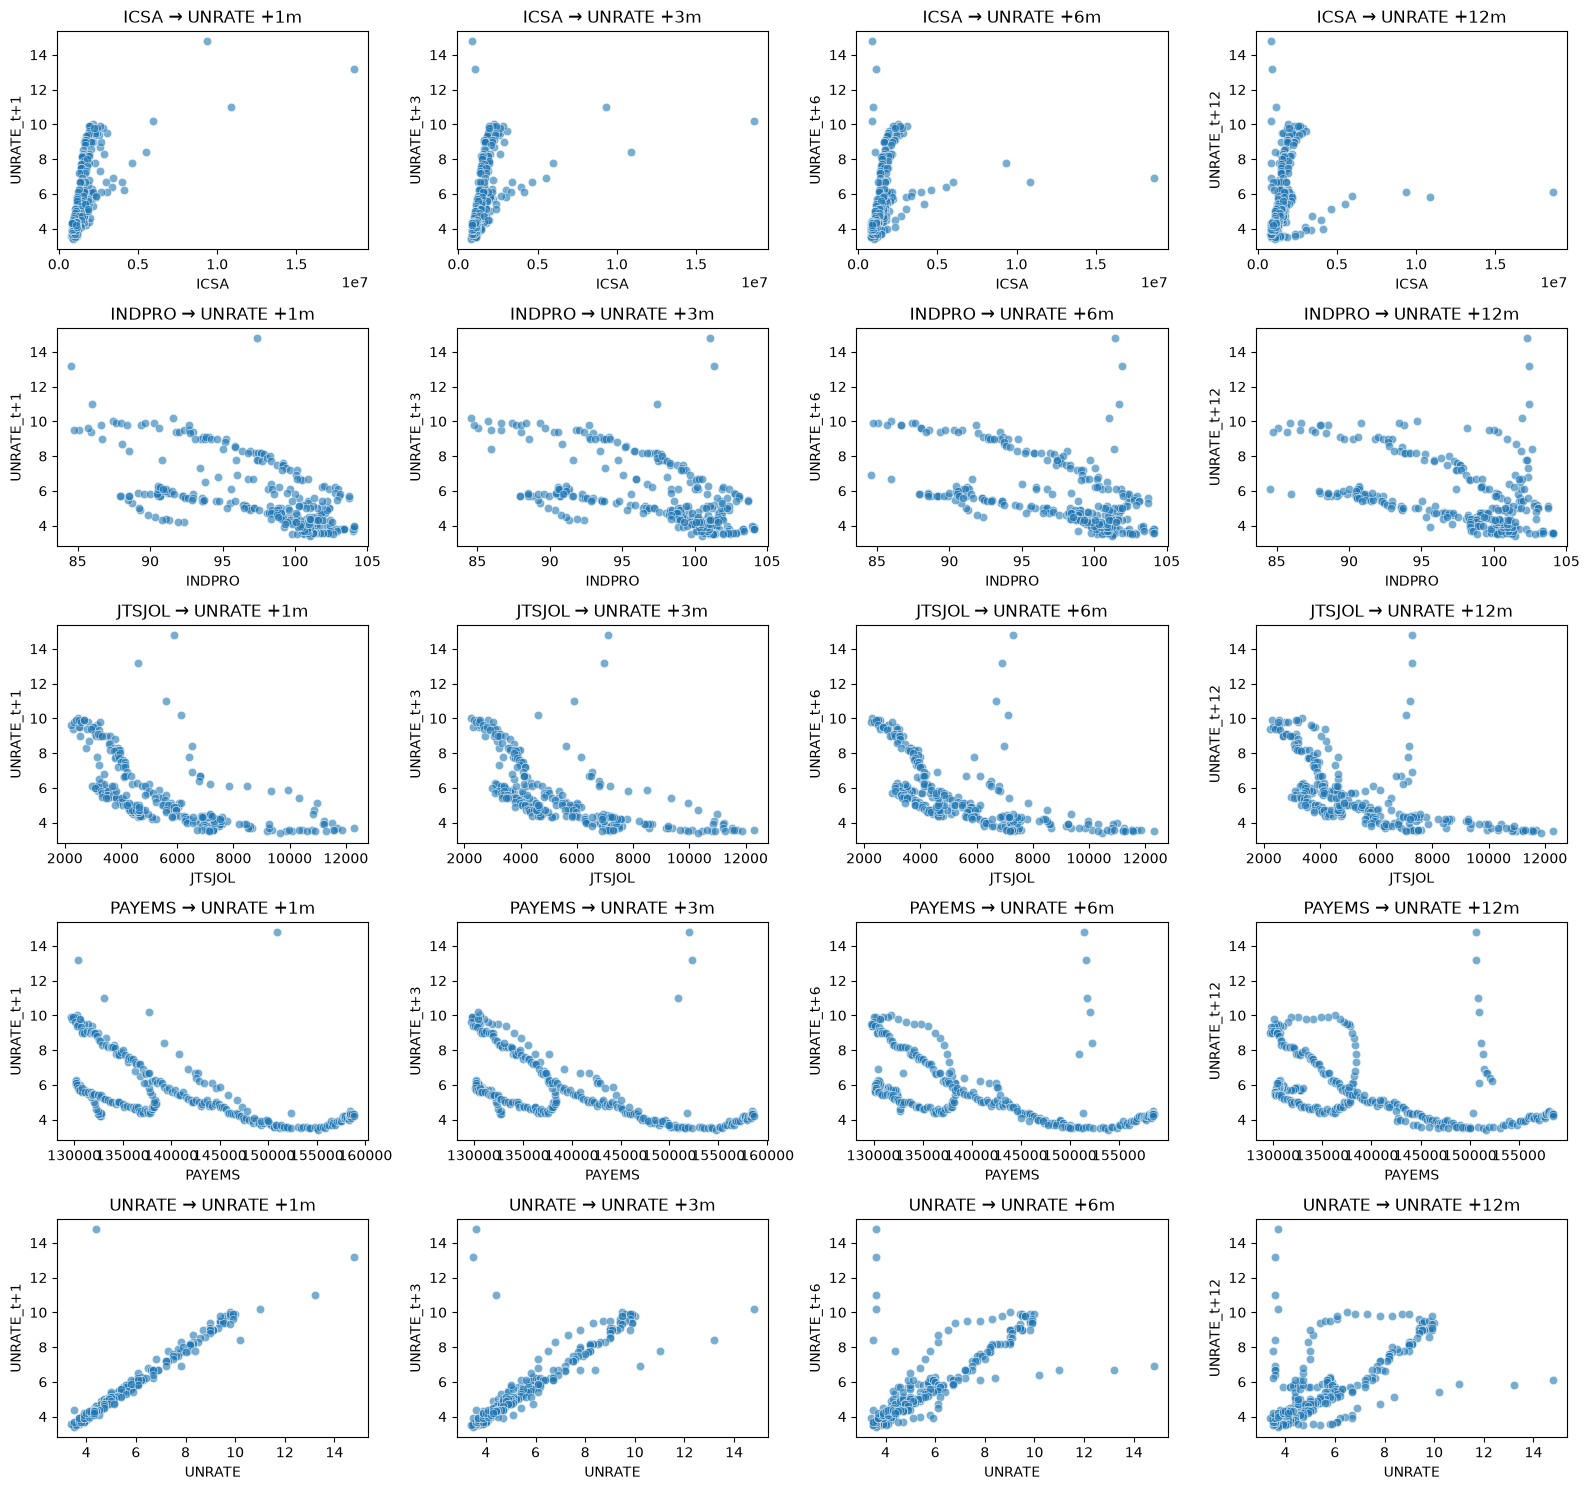

In [14]:
fig, axes = plt.subplots(
    len(features),
    len(time_frames),
    figsize=(16, 15)
)

for i, feature in enumerate(features):
    for j, t in enumerate(time_frames):
        sns.scatterplot(
            data=df_features,
            x=feature,
            y=f"UNRATE_t+{t}",
            ax=axes[i, j],
            alpha=0.6
        )

        axes[i, j].set_title(f"{feature} → UNRATE +{t}m")

plt.tight_layout()
plt.show()

Consider following models:
- Ridge regression -> L2 helps with multicollinearity
- Regression tree
- Random forest

**Extremely strong relationship between UNRATE and UNRATE t+n, which gets weaker the further the horizon is -> making mixed set would be useful**

### Final feature sets

In [ ]:
feature_set_levels = feature_set_levels
feature_set_changes = feature_set_changes

# mixed set changes + UNRATE levels
feature_set_mixed = feature_set_changes.copy() + ['UNRATE']

### Target sets

In [89]:
targets_set = ['UNRATE_t+1', 'UNRATE_t+3', 'UNRATE_t+6', 'UNRATE_t+12']

In [177]:
df_features[feature_set_log_levels + targets_set].corr()

,log10_ICSA,log10_INDPRO,log10_JTSJOL,log10_PAYEMS,log10_UNRATE,UNRATE_t+1,UNRATE_t+3,UNRATE_t+6,UNRATE_t+12
log10_ICSA,1.000000,-0.645246,-0.491525,-0.597869,0.727571,0.761582,0.623024,0.500415,0.366008
log10_INDPRO,-0.645246,1.000000,0.701721,0.723051,-0.619642,-0.612196,-0.576118,-0.533661,-0.441785
log10_JTSJOL,-0.491525,0.701721,1.000000,0.883632,-0.727522,-0.678736,-0.680475,-0.677852,-0.638122
log10_PAYEMS,-0.597869,0.723051,0.883632,1.000000,-0.718670,-0.635089,-0.594064,-0.553442,-0.491840
log10_UNRATE,0.727571,-0.619642,-0.727522,-0.718670,1.000000,0.936188,0.835952,0.734324,0.579836
UNRATE_t+1,0.761582,-0.612196,-0.678736,-0.635089,0.936188,1.000000,0.885110,0.764463,0.613676
UNRATE_t+3,0.623024,-0.576118,-0.680475,-0.594064,0.835952,0.885110,1.000000,0.839012,0.664187
UNRATE_t+6,0.500415,-0.533661,-0.677852,-0.553442,0.734324,0.764463,0.839012,1.000000,0.735163
UNRATE_t+12,0.366008,-0.441785,-0.638122,-0.491840,0.579836,0.613676,0.664187,0.735163,1.000000


### Export dict

In [173]:
sets_dict = {
    "levels": feature_set_levels,
    "changes": feature_set_changes,
    "log_10_levels": feature_set_log_levels,
    "mixed": feature_set_mixed,
    "targets": targets_set
}